In [ ]:
import pandas as pd

df = pd.read_excel("Telco_Customer_Churn.xlsx")

print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Telco_Customer_Churn.xlsx'

In [1]:
from google.colab import files
uploaded = files.upload()

Saving Telco Customer Churn.xlsx to Telco Customer Churn.xlsx


In [8]:

import pandas as pd

df = pd.read_excel("Telco Customer Churn.xlsx")
df.shape

(7043, 21)

In [7]:
import pandas as pd

df = pd.read_excel("Telco Customer Churn.xlsx")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
import pandas as pd

df = pd.read_excel("Telco Customer Churn.xlsx")
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [10]:
import pandas as pd

df = pd.read_excel("Telco Customer Churn.xlsx")
df.duplicated().sum()

np.int64(0)

In [11]:
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(tc.isna().sum())
df[tc.isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["TotalCharges"].dtype

dtype('float64')

In [13]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
No,5901
Yes,1142


In [14]:
cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"], errors="ignore")

for col in cat_cols:
    print(col, df[col].unique())

gender ['Female' 'Male']
SeniorCitizen ['No' 'Yes']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']


In [15]:
print(df["TotalCharges"].dtype, df["TotalCharges"].isna().sum())
print(df["SeniorCitizen"].unique())

float64 0
['No' 'Yes']


In [16]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# Overall churn rate
print(df["ChurnFlag"].mean().round(3))
df["Churn"].value_counts()

0.265


,count
Churn,
No,5174
Yes,1869


In [17]:
for col in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen", "Partner", "TechSupport"]:
    print(df.groupby(col)["ChurnFlag"].mean().round(3).sort_values(ascending=False))
    print()

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: ChurnFlag, dtype: float64

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: ChurnFlag, dtype: float64

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: ChurnFlag, dtype: float64

SeniorCitizen
Yes    0.417
No     0.236
Name: ChurnFlag, dtype: float64

Partner
No     0.330
Yes    0.197
Name: ChurnFlag, dtype: float64

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: ChurnFlag, dtype: float64



In [18]:
df["TenureBand"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

df.groupby("TenureBand", observed=True)["ChurnFlag"].agg(["mean", "count"]).round(3)

,mean,count
TenureBand,,
0-12,0.474,2186
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [19]:
df.groupby("Churn")[["MonthlyCharges", "tenure", "TotalCharges"]].mean().round(2)

,MonthlyCharges,tenure,TotalCharges
Churn,,,
No,61.27,37.57,2549.91
Yes,74.44,17.98,1531.80


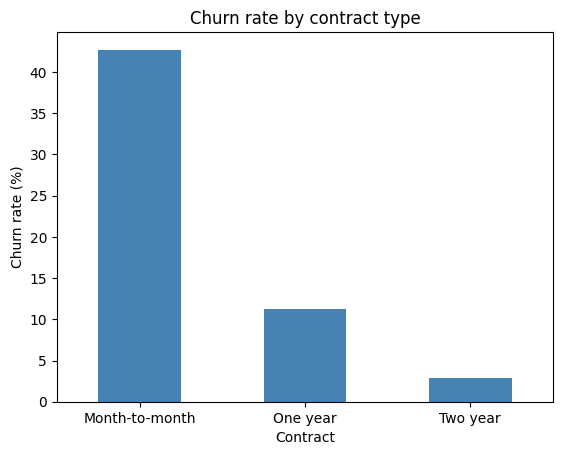

In [20]:
import matplotlib.pyplot as plt

(df.groupby("Contract")["ChurnFlag"].mean() * 100).plot(kind="bar", color="steelblue")
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by contract type")
plt.xticks(rotation=0)
plt.show()

In [21]:
total_monthly = df["MonthlyCharges"].sum()
lost_monthly = df.loc[df["Churn"] == "Yes", "MonthlyCharges"].sum()

print(f"Total monthly revenue: ${total_monthly:,.0f}")
print(f"Monthly revenue lost to churn: ${lost_monthly:,.0f}")
print(f"Share of revenue lost: {lost_monthly / total_monthly:.1%}")

Total monthly revenue: $456,117
Monthly revenue lost to churn: $139,131
Share of revenue lost: 30.5%


In [22]:
rev = (
    df[df["Churn"] == "Yes"]
    .groupby("Contract")["MonthlyCharges"]
    .agg(["count", "sum", "mean"])
    .round(2)
    .rename(columns={"count": "churned_customers", "sum": "monthly_revenue_lost", "mean": "avg_monthly_charge"})
)
rev

,churned_customers,monthly_revenue_lost,avg_monthly_charge
Contract,,,
Month-to-month,1655,120847.10,73.02
One year,166,14118.45,85.05
Two year,48,4165.30,86.78


In [23]:
risk = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic") &
    (df["PaymentMethod"] == "Electronic check")
]

print("Customers in segment:", len(risk))
print("Churn rate:", risk["ChurnFlag"].mean().round(3))
print("Share of all churners:", round(risk["ChurnFlag"].sum() / df["ChurnFlag"].sum(), 3))

Customers in segment: 1307
Churn rate: 0.604
Share of all churners: 0.422


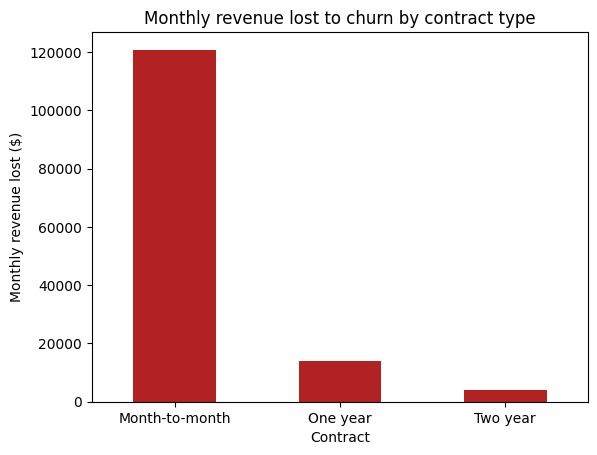

In [24]:
rev["monthly_revenue_lost"].plot(kind="bar", color="firebrick")
plt.ylabel("Monthly revenue lost ($)")
plt.title("Monthly revenue lost to churn by contract type")
plt.xticks(rotation=0)
plt.show()

In [25]:
# Drop columns the model shouldn't use
model_df = df.drop(columns=["customerID", "Churn", "TenureBand"])

# Merge "No internet/phone service" into plain "No"
model_df = model_df.replace({"No internet service": "No", "No phone service": "No"})

# Split into features (X) and target (y)
X = model_df.drop(columns="ChurnFlag")
y = model_df["ChurnFlag"]

# Convert category columns into 0/1 columns
cat_cols = X.select_dtypes(exclude="number").columns
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print(X.shape)
X.head()

(7043, 23)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,1,0,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,1
2,2,53.85,108.15,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,45,42.30,1840.75,1,0,0,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,2,70.70,151.65,0,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(y_train.mean().round(3), y_test.mean().round(3))

0.265 0.265


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC AUC:", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC AUC: 0.841


In [28]:
coefs = pd.Series(
    model.named_steps["logisticregression"].coef_[0],
    index=X.columns
).sort_values()

print("Reduce churn risk:\n", coefs.head(8))
print("\nIncrease churn risk:\n", coefs.tail(8))

Reduce churn risk:
 tenure               -1.155638
MonthlyCharges       -0.955323
InternetService_No   -0.661219
Contract_Two year    -0.616481
Contract_One year    -0.296230
OnlineSecurity_Yes   -0.119956
Dependents_Yes       -0.105281
TechSupport_Yes      -0.089751
dtype: float64

Increase churn risk:
 SeniorCitizen_Yes                 0.056460
PaperlessBilling_Yes              0.164906
PaymentMethod_Electronic check    0.188335
MultipleLines_Yes                 0.195288
StreamingTV_Yes                   0.260060
StreamingMovies_Yes               0.272765
TotalCharges                      0.488345
InternetService_Fiber optic       0.777051
dtype: float64


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)

print("ROC AUC:", round(roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]), 3))

pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

ROC AUC: 0.827


,0
TotalCharges,0.174497
tenure,0.163488
MonthlyCharges,0.161146
Contract_Two year,0.062401
InternetService_Fiber optic,0.054434
PaymentMethod_Electronic check,0.040690
Contract_One year,0.031562
InternetService_No,0.027139
PaperlessBilling_Yes,0.026128
gender_Male,0.025777


In [30]:
df.to_csv("telco_churn_cleaned.csv", index=False)

from google.colab import files
files.download("telco_churn_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary of Findings

**Dataset:** 7,043 telecom customers, 21 columns. Overall churn rate: ___%.

**Data cleaning:** 11 blank TotalCharges values (all customers with tenure 0)
were set to 0. SeniorCitizen was recoded to Yes/No for consistency.

**Key findings**
1. Contract type: month-to-month customers churn at ___%, versus ___% (one-year)
   and ___% (two-year).
2. Tenure: churn is highest in the first ___ months and falls as tenure grows.
3. Services and payment: ___ internet service and ___ payment method
   show the highest churn.
4. Revenue: churned customers account for ___% of monthly revenue ($___/month).
5. High-risk segment: month-to-month + fiber optic + electronic check
   = ___ customers with a ___% churn rate.

**Model:** Logistic regression reached a ROC AUC of ___; it caught ___% of
churners (recall). The strongest churn drivers were ___ and ___.

**Recommendations**
- Offer incentives to move month-to-month customers onto longer contracts.
- Focus retention efforts on the first ___ months of the customer lifecycle.
- Investigate why ___ customers churn more and whether it is a price,
  service quality, or onboarding problem.

**Limitations:** Single snapshot, no reason-for-leaving data, and correlation
is not causation.